# Tyre Degradation Model

### Project Context

One of the central challenges in Formula 1 race strategy is determining how tyre performance changes as a tyre set ages.

The more they are used, the more ther perfomance can deteriorate, potentially increasing lap times. 
Understanding this relationship is important when determining when a driver should pit and which tyre compound should be fitted.

### Objective

Develop and evaluate a predictive model that estimates lap-time performance at different tyre ages and helps quantify the effect of tyre degradation.

The model will use historical Formula 1 race data from the 2021–2025 seasons.

### Core Variables:

- `LapTime`: The target variable representing the amount of time the driver has taken to complete a lap.
- `TyreLife`: The main variable used to investigate how tyre age affects lap-time.
- `Compound`: Identifies the tyre compound being used.
- `Stint`: Identifies the period during which a driver uses a particular tyre set.

Additional variables will be investigated to account for other factors that may influence lap times.

In [21]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [3]:
df= pd.read_parquet("../Data/processed/all_laps_cleaned.parquet")
df.head()

,year,round,session,session_folder,event,country,location,event_date,Time,Driver,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,2021,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2021-03-28,0 days 00:39:09.674000,HAM,...,False,Mercedes,0 days 00:37:09.970000,2021-03-28 15:07:09.980,124,2.0,False,,False,False
1,2021,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2021-03-28,0 days 00:41:32.386000,HAM,...,False,Mercedes,0 days 00:39:09.674000,2021-03-28 15:09:09.684,4,2.0,False,,False,False
2,2021,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2021-03-28,0 days 00:44:09.042000,HAM,...,False,Mercedes,0 days 00:41:32.386000,2021-03-28 15:11:32.396,41,2.0,False,,False,False
3,2021,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2021-03-28,0 days 00:45:53.974000,HAM,...,False,Mercedes,0 days 00:44:09.042000,2021-03-28 15:14:09.052,126,2.0,False,,False,False
4,2021,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2021-03-28,0 days 00:47:39.113000,HAM,...,False,Mercedes,0 days 00:45:53.974000,2021-03-28 15:15:53.984,671,2.0,False,,False,False


In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (125046, 39)


<u>Checking the variables.</u>

In [ ]:
df[["LapTime", "TyreLife", "Compound", "Stint"]].head(10)

,LapTime,TyreLife,Compound,Stint
0,0 days 00:01:59.538000,4.0,MEDIUM,1.0
1,0 days 00:02:22.712000,5.0,MEDIUM,1.0
2,0 days 00:02:36.656000,6.0,MEDIUM,1.0
3,0 days 00:01:44.932000,7.0,MEDIUM,1.0
4,0 days 00:01:45.139000,8.0,MEDIUM,1.0
5,0 days 00:01:36.169000,9.0,MEDIUM,1.0
6,0 days 00:01:36.123000,10.0,MEDIUM,1.0
7,0 days 00:01:36.075000,11.0,MEDIUM,1.0
8,0 days 00:01:36.148000,12.0,MEDIUM,1.0
9,0 days 00:01:36.082000,13.0,MEDIUM,1.0


In [10]:
# Data types
df[["LapTime", "TyreLife", "Compound", "Stint"]].dtypes

LapTime     timedelta64[ns]
TyreLife            float64
Compound                str
Stint               float64
dtype: object

LapTime is stored as a time duration.

It might need to be converted into seconds because the regression models need numerical inputs and targets.

In [11]:
# Missing values.
df[["LapTime", "TyreLife", "Compound", "Stint"]].isna().sum()

LapTime     526
TyreLife    989
Compound    840
Stint       354
dtype: int64

<u>Checking compound distribution</u>


In [12]:
df["Compound"].value_counts(dropna=False)

Compound
HARD            54845
MEDIUM          45511
SOFT            15682
INTERMEDIATE     7675
NaN               840
WET               493
Name: count, dtype: int64

The first three are dry-weather compounds. They make up 116,038 observations, which is approximately 92.8% of the dataset.

We have enough data for developing an initial dry-tyre degradation model.

`INTERMEDIATE` and `WET` tyres will be treated separately because the conditions in which they are used differs from those of dry tyres.

<u>Checking tyre age</u>

In [13]:
df["TyreLife"].describe()

count    124057.000000
mean         14.658931
std          10.342469
min           1.000000
25%           7.000000
50%          13.000000
75%          21.000000
max          78.000000
Name: TyreLife, dtype: float64

- The average tyre age is approximately 14.7 laps.
- Half of the recorded tyre ages are 13 laps or lower.
- 75% of the observations have a tyre age of 21 laps or lower.
- The maximum is 78 laps, which is higher than the median.

<u>Checking tyre age across compounds</u>

In [14]:
df.groupby("Compound")["TyreLife"].describe()

,count,mean,std,min,25%,50%,75%,max
Compound,,,,,,,,
HARD,54699.0,16.868645,11.495004,1.0,8.0,15.0,24.0,78.0
INTERMEDIATE,7650.0,13.456471,9.557869,1.0,6.0,11.0,20.0,57.0
MEDIUM,45407.0,13.299447,9.273102,1.0,6.0,12.0,19.0,77.0
SOFT,15682.0,11.710114,7.504581,1.0,6.0,10.0,16.0,50.0
WET,493.0,7.764706,5.475130,1.0,3.0,6.0,12.0,21.0


`HARD` tyres have the highest average(approximately 16.87) age and their median(15.0) age is higher than that of the other compounds.

`SOFT` tyres have the lowest average(approximately 11.81) and median ages(10.0).

This suggests that `HARD` tyres were used for longer than `MEDIUM` and `SOFT` tyres.

But we cannot conclude that `HARD` tyres degrade more slowly because they are used for a longer period of time. These statistics tell us about tyre usage, not tyre degradation

The maximum tyre ages are high:
- `HARD`: 78 laps.
- `MEDIUM`: 77 laps.
- `SOFT`: 50 laps.

<u>Preparing the initial modelling dataset</u>

The initial model will focus on dry tyres and exclude:
- Records without lap times or tyre ages.
- Laps marked inaccurate.
- Deleted laps.
- Pit-entry and pit-exit laps.
- Records without stint information.

In [15]:
dry_compounds = ["HARD", "MEDIUM", "SOFT"]

model_df = df[
    (df["Compound"].isin(dry_compounds)) &
    (df["LapTime"].notna()) &
    (df["TyreLife"].notna()) &
    (df["Stint"].notna()) &
    (df["IsAccurate"] == True) &
    (df["Deleted"] == False) &
    (df["PitInTime"].isna()) &
    (df["PitOutTime"].isna())
].copy()

print("Original dataset:", df.shape)
print("Modelling dataset:", model_df.shape)

Original dataset: (125046, 39)
Modelling dataset: (99863, 39)


The dataset for modelling is made up of 99,863 rows and 39 columns.

<u>Checking track conditions<u>

In [16]:
model_df["TrackStatus"].value_counts(dropna=False)

TrackStatus
1     97218
12     2314
21      259
2        72
Name: count, dtype: int64

- 1 means the track clear.
- 2 means a yellow flag.
- 12 means the track clear and a yellow flag occured during the lap.
- 21 means yellow flag and track clear occured during the lap.

The number of records where the track status is track clear(1) are	97,218

The number of records where the track status yellow affected(2, 12, 21)	are 2,645

Approximately 97.35% of our modelling observations occurred under clear-track conditions and the remaing had a yellow flag condition.

For the initial model, only laps recorded under clear track conditions will be used to understand how tyre age affects lap-time performance under normal racing conditions.

In [18]:
model_df = model_df[model_df["TrackStatus"] == "1"].copy()

model_df.shape

(97218, 39)

The modeling dataset now has a shape of 97,218 rows and 39 columns

<u>Convert lap time to seconds</u>

Having lap time seconds will make it easier to calculate averages, compare lap times, visualise degradation and train regression models


A new column called LapTimeSeconds will be created to store the lap time in seconds.

In [19]:
model_df["LapTimeSeconds"] = model_df["LapTime"].dt.total_seconds()

model_df["LapTimeSeconds"].head(10)

5     96.169
6     96.123
7     96.075
8     96.148
9     96.082
10    96.143
11    96.507
14    94.057
15    95.104
16    95.099
Name: LapTimeSeconds, dtype: float64

<u>Checking an actual tyre stint</u>

Lap times differ between circuits. This means 90-second lap at one circuit isn't directly comparable to a 90-second lap in another circuit.

In [20]:
bahrain_stint = model_df[
    (model_df["year"] == 2021) &
    (model_df["event"] == "Bahrain Grand Prix") &
    (model_df["Driver"] == "HAM") &
    (model_df["Stint"] == 1)
]

bahrain_stint[["LapNumber", "TyreLife", "Compound", "LapTimeSeconds"]].sort_values("TyreLife")

,LapNumber,TyreLife,Compound,LapTimeSeconds
5,6.0,9.0,MEDIUM,96.169
6,7.0,10.0,MEDIUM,96.123
7,8.0,11.0,MEDIUM,96.075
8,9.0,12.0,MEDIUM,96.148
9,10.0,13.0,MEDIUM,96.082
10,11.0,14.0,MEDIUM,96.143
11,12.0,15.0,MEDIUM,96.507


- The fastest lap was at tyre age 11 (96.075 seconds).
- Lap times fluctuate a bit and do not increasing consistently.
- At tyre age 15, lap time increased to 96.507 seconds.

The difference between the fastest and slowest observations is 0.432 seconds.

The entire difference cannot be because of tyre degradation because other factors, including driving behaviour and race conditions, can influence individual lap times.

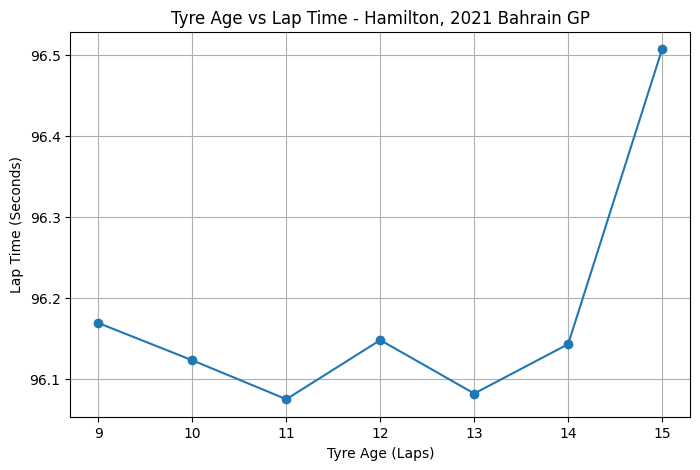

In [22]:

bahrain_stint = bahrain_stint.sort_values("TyreLife")

plt.figure(figsize=(8, 5))

plt.plot(bahrain_stint["TyreLife"], bahrain_stint["LapTimeSeconds"], marker="o")

plt.title("Tyre Age vs Lap Time - Hamilton, 2021 Bahrain GP")
plt.xlabel("Tyre Age (Laps)")
plt.ylabel("Lap Time (Seconds)")
plt.grid(True)

plt.show()

- From tyre age 9 to 11, lap times actually improve.
- From age 11 to 14, lap time fluctuates around 96.1 seconds.
- At age 15, lap time increases to 96.507 seconds.

Lap times don't necessarily increase with every additional lap of tyre age.

The final observation is slower but it cannot be conluded that this is due to tyre degradation since other factors might have influenced that lap.

<u>Checking how many stints there are</u>

In [23]:
stint_counts = model_df.groupby(["year", "round", "Driver", "Stint"]).size()

stint_counts.describe()

count    5146.000000
mean       18.891955
std        10.567309
min         1.000000
25%        11.000000
50%        18.000000
75%        25.000000
max        75.000000
dtype: float64

- There 5,146 individual driver-race stints.
- Half of these stints contain at least 18 usable lap observations.
- The middle 50% of stints contain between 11 and 25 usable laps.
- Some stints have only one usable lap, while the longest has 75.

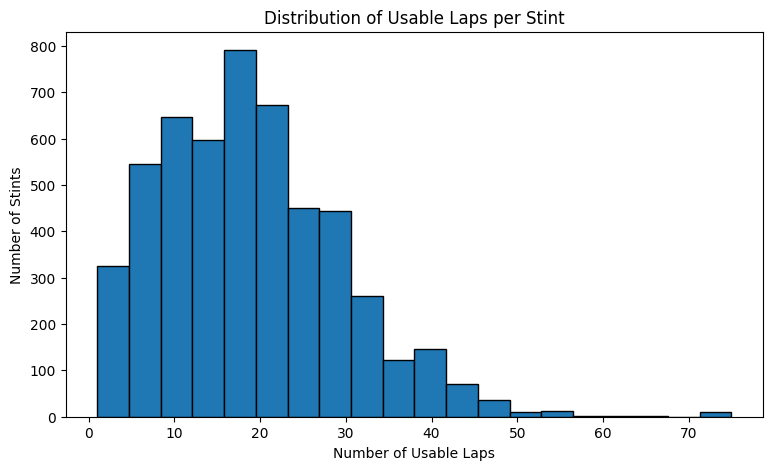

In [24]:
plt.figure(figsize=(9, 5))

plt.hist(stint_counts, bins=20, edgecolor="black")

plt.title("Distribution of Usable Laps per Stint")
plt.xlabel("Number of Usable Laps")
plt.ylabel("Number of Stints")

plt.show()

- Most stints contain between 5 and 30 usable laps.
- The most common range is approximately 16–20 laps.
- Longer stints become increasingly uncommon.
- A few stints are exceptionally long.

Short stints might not be actual short tyre runs since the filtering done earlier may have excluded some laps from longer stints.

<u>Check stint lengths across compounds</u>

In [25]:
stint_lengths = model_df.groupby(["year", "round", "Driver", "Stint", "Compound"]).size().reset_index(name="UsableLaps")

stint_lengths.groupby("Compound")["UsableLaps"].describe()

,count,mean,std,min,25%,50%,75%,max
Compound,,,,,,,,
HARD,1970.0,23.990863,11.037538,1.0,17.0,23.0,31.0,75.0
MEDIUM,2213.0,17.012201,9.162356,1.0,10.0,16.0,23.0,74.0
SOFT,963.0,12.780893,7.489339,1.0,7.0,12.0,18.0,42.0


- `HARD`: Has the longest average(approximately 23.99) and median(23.0) stint lengths.
- `MEDIUM`: Has the largest number of individual stints(2,213).
- `SOFT`: Has the shortest average(approximately 12.78) and median(12) stint lengths.

<u>Investigating how a drivers lap time changes as the tyres age.</u>

We will check how laps changge withing individual stints.

The first 3 usable laps will be used to calculate a reference lap time.

The other laps will be compared against the reference lap time to determine if they were faster or slower.

Since filtering may have removed earlier laps, this isn't necessarily the tyre's performance when brand new.

This way we can compare changes in performance instead of lap times.

*This is a measure of change in observed pace, not pure tyre degradation. Factors like fuel consumption, changing track conditions and driver behaviour can still influence it.*

In [26]:
# Identify individual stints
stint_keys = ["year", "round", "event", "Driver", "Stint"]

# Arrange laps in order within each stint
model_df = model_df.sort_values(stint_keys + ["LapNumber"]).copy()

# Get the first three usable laps from each stint
first_three_laps = model_df.groupby(stint_keys).head(3)

# Calculate the average lap time of those first three laps
stint_baselines = first_three_laps.groupby(stint_keys)["LapTimeSeconds"].mean()

# Add each stint's reference lap time to the original observations
model_df = model_df.join(stint_baselines.rename("BaselineLapTime"), on=stint_keys)

# Calculate the difference from the reference lap time
model_df["LapTimeDelta"] = (model_df["LapTimeSeconds"] - model_df["BaselineLapTime"])

In [27]:
model_df[["year", "event", "Driver", "LapNumber", "TyreLife", "Compound", "LapTimeSeconds", "BaselineLapTime", "LapTimeDelta"]].head(10)

,year,event,Driver,LapNumber,TyreLife,Compound,LapTimeSeconds,BaselineLapTime,LapTimeDelta
999,2021,Bahrain Grand Prix,ALO,6.0,9.0,SOFT,97.652,97.674667,-0.022667
1000,2021,Bahrain Grand Prix,ALO,7.0,10.0,SOFT,97.366,97.674667,-0.308667
1001,2021,Bahrain Grand Prix,ALO,8.0,11.0,SOFT,98.006,97.674667,0.331333
1002,2021,Bahrain Grand Prix,ALO,9.0,12.0,SOFT,99.062,97.674667,1.387333
1003,2021,Bahrain Grand Prix,ALO,10.0,13.0,SOFT,97.758,97.674667,0.083333
1006,2021,Bahrain Grand Prix,ALO,13.0,2.0,MEDIUM,96.844,97.144667,-0.300667
1007,2021,Bahrain Grand Prix,ALO,14.0,3.0,MEDIUM,97.143,97.144667,-0.001667
1008,2021,Bahrain Grand Prix,ALO,15.0,4.0,MEDIUM,97.447,97.144667,0.302333
1009,2021,Bahrain Grand Prix,ALO,16.0,5.0,MEDIUM,97.183,97.144667,0.038333
1010,2021,Bahrain Grand Prix,ALO,17.0,6.0,MEDIUM,97.797,97.144667,0.652333


A positive difference means slower than the reference pace. A negative difference means faster.

<u>Checking how lap time difference changes with tyre age across all 3 compounds</u>

In [28]:
degradation_summary = model_df.groupby(["Compound", "TyreLife"])["LapTimeDelta"].median()

degradation_summary

Compound  TyreLife
HARD      1.0        -0.022667
          2.0         0.006167
          3.0        -0.006500
          4.0        -0.023667
          5.0        -0.042667
                        ...   
SOFT      45.0        0.480333
          46.0       -0.201667
          47.0       -0.555667
          48.0       -0.549667
          49.0       -0.786667
Name: LapTimeDelta, Length: 203, dtype: float64

There are 203 compound–tyre-age combinations across the three dry compounds.

Some older tyres have negative median values. This could be a result of other factors such as race conditions.

<u>Checking how many laps contributed to each result</u>

In [30]:
degradation_summary = model_df.groupby(["Compound", "TyreLife"])["LapTimeDelta"].agg(["median", "count"])

degradation_summary

median  count
Compound TyreLife                 
HARD     1.0      -0.022667      6
         2.0       0.006167   1372
         3.0      -0.006500   1600
         4.0      -0.023667   1623
         5.0      -0.042667   1687
...                     ...    ...
SOFT     45.0      0.480333      1
         46.0     -0.201667      1
         47.0     -0.555667      1
         48.0     -0.549667      1
         49.0     -0.786667      1

[203 rows x 2 columns]


The median lap-time differences vary across tyre compounds and tyre ages. The number of observations supporting each median also varies.

For example, `HARD` tyres have over 1,300 observations at each of tyre ages 2–5, whereas the observations for `SOFT` tyres at ages 45–49 consist of only one lap each.

Sample size will need to be considered when interpreting results. Median values calculated from very few observations may not represent reliable performance patterns.

Therefore, observations at tyre ages with insufficient sample sizes should be made carefully.

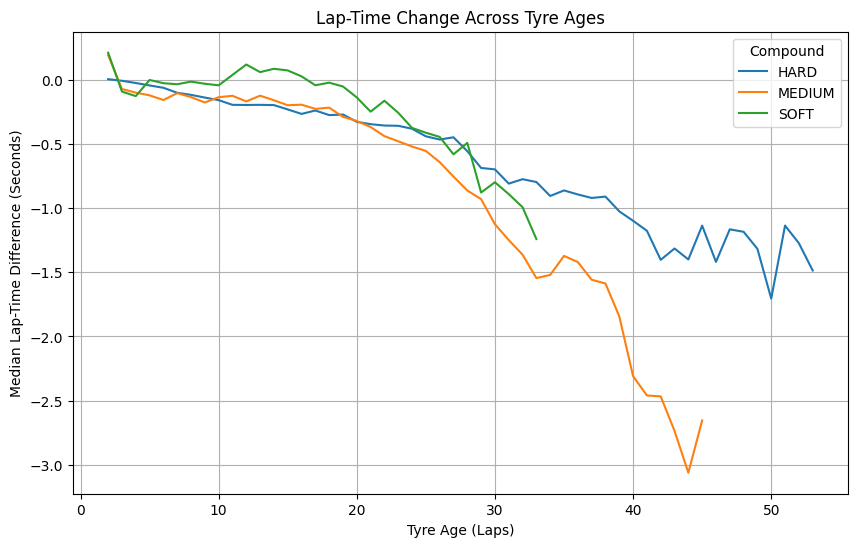

In [31]:
plot_data = degradation_summary[degradation_summary["count"] >= 30]

plot_data = plot_data["median"].unstack(level=0)

plot_data.plot(figsize=(10, 6))

plt.title("Lap-Time Change Across Tyre Ages")
plt.xlabel("Tyre Age (Laps)")
plt.ylabel("Median Lap-Time Difference (Seconds)")
plt.grid(True)
plt.legend(title="Compound")

plt.show()